# 🌱 Lesson 6: Data Leakage
**Phase 2 · Data Preprocessing & Feature Engineering** &nbsp;|&nbsp; ⏱ about 3 hours &nbsp;|&nbsp; 📚 Prerequisite: Lessons 01–05

> *The model that aced the exam, because it had the answer key.*

## 🎯 By the end of this lesson you will be able to
- Define data leakage and explain why it produces misleading results.
- Recognise six kinds: target, train-test contamination, selection, temporal, group and duplicate leakage.
- Reproduce leakage experimentally and *measure* its damage.
- Apply the golden rule: split first, `fit` on training data only, `transform` everything else.
- Use Pipelines, `TimeSeriesSplit` and `GroupKFold` to prevent leakage, and a checklist to audit existing work.

---

In [1]:
import sys
sys.path.append("../utils")            # lets us import course_utils.py and agri_prep.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from course_utils import *             # load_raw_farm, profile, setup_plots, ...

setup_plots()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
np.random.seed(42)

In [2]:
from sklearn.model_selection import train_test_split, cross_val_score, KFold, GroupKFold, TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.feature_selection import SelectKBest, f_classif

fe = build_farm_features(load_lesson_clean())
print(fe.shape)

(2329, 36)


# Part 1 · The story of the cheating student

A teacher wants to know whether a student *understands* maths. She gives a practice test, then a final exam. A *new* student scores 100% on the final. Brilliant!

...except the final exam questions were **in the practice test**. The student didn't learn maths; he memorised the paper.

> **Data leakage** is when information from outside the training data (usually from the *test set*, the *future*, or the *target itself*) sneaks into the model-building process. The model looks fantastic in evaluation and **fails in the real world**, because the real world doesn't hand you the answer key.

### Why it's so dangerous
1. It raises **no error**. The code runs, the metrics are great.
2. The more you tune, the better it looks: you are optimising against a rigged test.
3. The failure shows up **months later**, in production, after decisions were made.

### The six faces of leakage

| # | Type | One-line example | Typical severity |
|---|---|---|---|
| 1 | **Target leakage** | Predicting yield with a column computed *from* yield (revenue) | 🔥🔥🔥 catastrophic |
| 2 | **Train-test contamination** | Fitting a scaler / imputer / PCA on all rows before splitting | 🔥 usually mild (but wrong) |
| 3 | **Selection leakage** | Choosing "best features" using all rows, then cross-validating | 🔥🔥🔥 severe on small/wide data |
| 4 | **Temporal leakage** | Centered rolling windows; random split of time series | 🔥🔥 severe |
| 5 | **Group leakage** | Same farm in both train and test | 🔥–🔥🔥 depends on data |
| 6 | **Duplicate leakage** | Same record on both sides of the split (why Lesson 1 de-duplicated!) | 🔥 – 🔥🔥 |

We'll *reproduce* each, so that you recognise the smell.

---
# Part 2 · Target leakage: the answer hidden in a column

### The timeline test
For every column ask: **at the moment I make the prediction, do I know this?** Suppose we want to predict yield **at planting time** so a farmer can plan:

| Column | Known when? | Safe to use? |
|---|---|---|
| county, soil_type, farm_size, experience | before planting | ✅ |
| crop, planting_date, fertilizer plan, irrigation | at planting | ✅ |
| rainfall_mm, avg_temp_c, pest_pressure | **during** the season (so we'd need a *forecast*) | ⚠️ depends on the use-case |
| harvest_date | at harvest | ❌ |
| market_price_ksh_kg | at sale | ❌ |
| total_revenue_ksh | after sale | ❌❌ computed from the answer |

*What you may use depends on **when** the prediction is made.* That decision belongs in your documentation.

> 🔍 **Auditing our own work.** In Lessons 4–5 we happily used `grow_days` (harvest − planting) as a feature. By this timeline the *actual* harvest date is unknown at planting, so for a planting-time model `grow_days` is a mild leak (a crop's typical duration is already captured by `crop`). We kept it earlier because those lessons were about *technique*; the **Lesson 7 pipeline and the project drop it**. Spotting this in your own earlier code is exactly the habit this lesson is trying to build.

### Experiment: what does a leaky column do?
A well-meaning analyst adds "revenue per hectare" (revenue ÷ farm size) as a feature. Let's compare three models: honest, with raw revenue, with revenue-per-hectare.

In [3]:
base = ["rainfall_mm", "avg_temp_c", "soil_ph", "nitrogen_ppm", "organic_matter_pct", "fertilizer_kg_ha", "farm_size_ha",
        "irrigation", "rain_gap_sq", "temp_gap_sq", "ph_gap_sq", "pest_ord", "exp_ord", "grow_days"]
Xh = fe[base].join(pd.get_dummies(fe["crop"], dtype=float))
y = fe["yield_t_ha"]

fe["revenue_per_ha"] = fe["total_revenue_ksh"] / fe["farm_size_ha"]          # "helpful" derived column
variants = {
    "honest features": Xh,
    "+ total_revenue_ksh": Xh.assign(total_revenue_ksh=fe["total_revenue_ksh"]),
    "+ revenue_per_ha": Xh.assign(revenue_per_ha=fe["revenue_per_ha"]),
}
rf = RandomForestRegressor(200, min_samples_leaf=3, n_jobs=-1, random_state=0)
scores = {k: cross_val_score(make_pipeline(SimpleImputer(strategy="median"), rf), v, y, cv=5, scoring="r2").mean()
          for k, v in variants.items()}
display(pd.Series(scores).round(3).to_frame("5-fold CV R²"))

# ...and no machine learning at all: undo the arithmetic with one line
from sklearn.metrics import r2_score
implied = fe["revenue_per_ha"] / (1000 * fe["market_price_ksh_kg"])
ok = implied.notna()
print(f"A one-line formula (revenue_per_ha / 1000 / price) recovers yield with R² = {r2_score(y[ok], implied[ok]):.3f}")

,5-fold CV R²
honest features,0.905
+ total_revenue_ksh,0.914
+ revenue_per_ha,0.949


A one-line formula (revenue_per_ha / 1000 / price) recovers yield with R² = 0.991


Three lessons hide in this output:

1. **A column that merely repackages the answer lifts the score** (≈ 0.905 → ≈ 0.949 for `revenue_per_ha`): an improvement that would evaporate in production.
2. **The simple formula reveals the real size of the leak:** divide revenue-per-hectare by the price and you get yield almost exactly (R² ≈ 0.99) *without any model*. The forest only partly exploited it because the price varies from sale to sale: a cleverer model or a log-transform would exploit it fully.
3. **Raw `total_revenue_ksh` barely changes the score**: the forest struggles to undo a multiplication by farm size. That *looks* harmless, but it is not: **leaks hide**. Never rely on a model's *failure* to exploit one.

### How to *detect* target leakage
- **Too good to be true:** scores far above any sensible baseline.
- **Feature importance dominated by one feature**: especially a post-event one.
- **Reconstruct the target:** can a formula of a feature recover it?

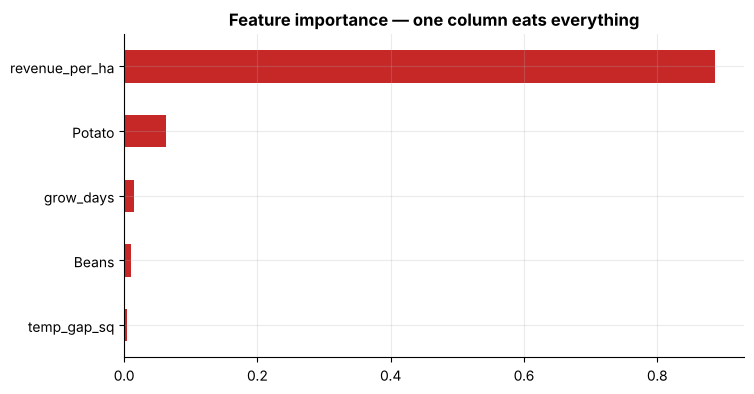

In [4]:
leaky_rf = RandomForestRegressor(200, min_samples_leaf=3, n_jobs=-1, random_state=0)
Xl = variants["+ revenue_per_ha"]
leaky_rf.fit(SimpleImputer(strategy="median").fit_transform(Xl), y)
pd.Series(leaky_rf.feature_importances_, index=Xl.columns).sort_values().tail(5).plot.barh(color="#C62828", title="Feature importance: one column eats everything")
plt.show()

### Prevention
- Write a **data dictionary with a "known at" column** for every field (see `data/DATA_DICTIONARY.md`).
- **Exclude** post-event columns *before* modelling, not after seeing the scores.
- Be extra wary of derived columns with *ratios, totals or aggregates* involving the target.

---
# Part 3 · Train–test contamination: preprocessing fitted on everything

Remember the two verbs: **`fit`** *learns* from data (a mean, a min, a median, PCA directions); **`transform`** *applies* what was learned.

> **Golden rule: `fit` sees only training data. `transform` can be applied to anything.**

Why? The test set stands in for *future, unseen* data. Anything the model-building process learns from the test rows is knowledge it could never have in real life.

### What the scaler "knew"
We'll put the farm with the largest area in the test set and see what each scaler learned:

In [5]:
sizes = fe[["farm_size_ha"]].dropna()
biggest = sizes["farm_size_ha"].idxmax()
test_idx = [biggest] + sizes.drop(biggest).sample(100, random_state=0).index.tolist()
test_s, train_s = sizes.loc[test_idx], sizes.drop(test_idx)

leaky  = MinMaxScaler().fit(sizes)         # ❌ fitted on ALL rows (test included)
honest = MinMaxScaler().fit(train_s)       # ✅ fitted on TRAIN only

pd.DataFrame({
    "learned max (ha)":               [leaky.data_max_[0], honest.data_max_[0]],
    "scaled TRAIN median":            [np.median(leaky.transform(train_s)), np.median(honest.transform(train_s))],
    "scaled TEST maximum":            [leaky.transform(test_s).max(), honest.transform(test_s).max()],
}, index=["leaky (fit on all)", "honest (fit on train)"]).round(4)

,learned max (ha),scaled TRAIN median,scaled TEST maximum
leaky (fit on all),377.7,0.0026,1.0000
honest (fit on train),338.8,0.0029,1.1149


In the leaky version the giant test farm **reshaped how the training farms were scaled** (the learned maximum is 378 ha) and the test data looks perfectly in-range (max = 1.0). In the honest version the test farm is correctly seen as a **surprise** (scaled above 1), which is exactly what the model will experience when a new giant farm appears in production.

### Wrong vs right, side by side
```python
# ❌ WRONG: statistics learned from ALL data                  # ✅ RIGHT: learn from train, apply to both
scaler = StandardScaler()                                     X_train, X_test, y_train, y_test = train_test_split(X, y)
X_all = scaler.fit_transform(X)                               scaler = StandardScaler()
X_train, X_test = train_test_split(X_all)                     X_train_s = scaler.fit_transform(X_train)   # fit + transform
                                                              X_test_s  = scaler.transform(X_test)        # transform ONLY
```
Never call `fit` or `fit_transform` on test data. **This applies to *everything* learned from data:** scalers, imputers (the medians!), encoders (categories, target means), PCA, feature selectors, outlier caps, power transforms, bin edges.

> **How bad is it?** For plain scaling or median imputation on a large dataset, the numerical damage is usually small: see Problem 6.2. It is *much* worse for steps that use the **target** (feature selection, target encoding) or on small datasets, as the next experiment shows. Do it right everywhere: it costs nothing.

---
# Part 4 · Selection leakage: the most dramatic demonstration

Here is a classic experiment from statistical-learning textbooks. We create **pure noise**: 100 samples, 5,000 random features and **random yes/no labels**. There is *nothing* to learn: the best possible accuracy is 50%.

Method A (wrong): pick the 20 features most correlated with the labels using **all 100 rows**, *then* cross-validate.
Method B (right): put the selector **inside** a pipeline, so each fold picks features from its own training rows.

A: select first (WRONG)    0.874
B: pipeline (RIGHT)        0.504


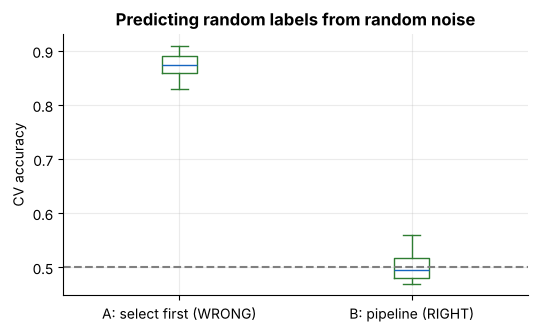

In [6]:
rng = np.random.default_rng(0)
rows = []
for rep in range(10):
    Xn = rng.normal(size=(100, 5000))
    yn = rng.integers(0, 2, 100)

    Xsel = SelectKBest(f_classif, k=20).fit_transform(Xn, yn)                     # ❌ selection sees all labels
    wrong = cross_val_score(LogisticRegression(max_iter=1000), Xsel, yn, cv=5).mean()

    pipe = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=1000))   # ✅ inside CV
    right = cross_val_score(pipe, Xn, yn, cv=5).mean()
    rows.append((wrong, right))

res = pd.DataFrame(rows, columns=["A: select first (WRONG)", "B: pipeline (RIGHT)"])
print(res.mean().round(3).to_string())
res.plot.box(figsize=(6, 3.4)); plt.axhline(0.5, color="grey", ls="--"); plt.ylabel("CV accuracy"); plt.title("Predicting random labels from random noise"); plt.show()

Method A reports ≈ **87% accuracy** on labels that are **pure coin flips**. With 5,000 candidate columns, a few are *bound* to correlate with 100 random labels by chance; selecting them with all the labels in view, then "validating" on the same rows, certifies luck as skill. Method B correctly reports ≈ 50%.

> This is why every serious ML workflow keeps selection, scaling and imputation **inside** the pipeline that cross-validation re-fits on every fold; Lesson 7.

---
# Part 5 · Temporal leakage: peeking into the future

Time-series data has an arrow. Using information from *after* the prediction moment is leakage, and it can sneak in through innocent-looking code.

### The centered rolling window
Task: predict **tomorrow's maize price**. Two features built from the same data:
- **trailing** 7-day mean: days *t−6 … t* (all known today) ✅
- **centered** 7-day mean: days *t−3 … t+3* (includes tomorrow!) ❌

In [7]:
prices = load_prices()
m = prices[prices["crop"] == "Maize"].sort_values("date").reset_index(drop=True)
spike = m["price_ksh_kg"] > 1.5 * m["price_ksh_kg"].shift(1).rolling(7, min_periods=3).median()
m["price"] = m["price_ksh_kg"].mask(spike).ffill()

m["trailing7"] = m["price"].rolling(7).mean()
m["centered7"] = m["price"].rolling(7, center=True).mean()      # ❌ looks at t+1, t+2, t+3
m["target"]    = m["price"].shift(-1)                           # tomorrow
m = m.dropna(subset=["price", "trailing7", "centered7", "target"])

train, test = m[m["date"] < "2023-01-01"], m[m["date"] >= "2023-01-01"]
mae = {"naive (tomorrow = today)": (test["target"] - test["price"]).abs().mean()}
for name, cols in {"trailing window ✅": ["price", "trailing7"], "centered window ❌": ["price", "centered7"]}.items():
    mod = LinearRegression().fit(train[cols], train["target"])
    mae[name] = (test["target"] - mod.predict(test[cols])).abs().mean()
pd.Series(mae).round(3).to_frame("MAE (KSh/kg), 2023")

,"MAE (KSh/kg), 2023"
naive (tomorrow = today),0.588
trailing window ✅,0.583
centered window ❌,0.504


The honest trailing feature barely beats guessing "tomorrow = today" (next-day prices are very predictable from today). The centered feature appears to cut the error by ~15%. It has done nothing clever: it simply **averaged tomorrow's price into the input**. In production, the centered window would be missing its right half.

### Random splits on time data
Shuffling rows before splitting lets the model train on March 2023 and be tested on January 2023. Neighbouring days are nearly identical, so the model effectively "interpolates" between known days: impossible for the real future. **Rule:** split chronologically (train on the past, test on the future), leave a **gap** equal to the forecast horizon, and use `TimeSeriesSplit` for cross-validation:

In [8]:
tscv = TimeSeriesSplit(n_splits=4)
dates = m["date"].reset_index(drop=True)
for i, (tr, te) in enumerate(tscv.split(m), 1):
    print(f"fold {i}: train {dates[tr[0]].date()} → {dates[tr[-1]].date()}   |   test {dates[te[0]].date()} → {dates[te[-1]].date()}")

fold 1: train 2019-01-07 → 2020-01-06   |   test 2020-01-07 → 2021-01-03
fold 2: train 2019-01-07 → 2021-01-03   |   test 2021-01-04 → 2022-01-01
fold 3: train 2019-01-07 → 2022-01-01   |   test 2022-01-02 → 2022-12-30
fold 4: train 2019-01-07 → 2022-12-30   |   test 2022-12-31 → 2023-12-28


Each fold trains on an expanding past and tests on the following future. No fold ever tests on data older than its training data.

---
# Part 6 · Group and duplicate leakage

### Group leakage
Our dataset has **four seasons per farm**. If a farm's 2020 record is in training and its 2022 record in test, the model may exploit "I have seen this farm". Rows aren't independent. Let's *see* how it plays out:

In [9]:
Xg = Xh.copy()
groups = fe["farm_id"]
rf = RandomForestRegressor(200, min_samples_leaf=3, n_jobs=-1, random_state=0)

# how many farms appear on BOTH sides of a random split?
tr_idx, te_idx = next(KFold(5, shuffle=True, random_state=0).split(Xg))
shared = set(groups.iloc[tr_idx]) & set(groups.iloc[te_idx])
print(f"random KFold: {len(shared)} of {groups.iloc[te_idx].nunique()} test farms also appear in training")

tr_idx, te_idx = next(GroupKFold(5).split(Xg, groups=groups))
print(f"GroupKFold  : {len(set(groups.iloc[tr_idx]) & set(groups.iloc[te_idx]))} shared farms")

pipe = make_pipeline(SimpleImputer(strategy="median"), rf)
rand_cv  = cross_val_score(pipe, Xg, np.log(y), cv=KFold(5, shuffle=True, random_state=0), scoring="r2").mean()
group_cv = cross_val_score(pipe, Xg, np.log(y), cv=GroupKFold(5), groups=groups, scoring="r2").mean()
print(f"\nCV R² with random KFold: {rand_cv:.3f}  |  with GroupKFold: {group_cv:.3f}")

random KFold: 348 of 350 test farms also appear in training
GroupKFold  : 0 shared farms



CV R² with random KFold: 0.937  |  with GroupKFold: 0.934


Here the two scores are **almost identical**: and that is an honest, instructive result. In this *simulated* data, a farm's yield depends only on measured columns (weather, soil, crop...), so recognising the farm teaches the model nothing extra. In **real** data there are *unmeasured* farm effects (farmer skill, micro-climate, management) that the model can memorise, and the gap between random and grouped CV can be large.

> **Practical rule:** when rows share an identity (farm, patient, customer, machine), *use `GroupKFold` anyway*. If the scores agree, you've lost nothing. If they differ, you've just avoided shipping a fantasy.

### Duplicate leakage
Exact or near-duplicate rows on both sides of a split give the model a free look at the test answers. That's why Lesson 1 spent time on near-duplicates: de-duplicate **before** splitting.

---
# Part 7 · The prevention playbook

### The correct pattern: a Pipeline inside cross-validation
Everything that learns from data goes **inside** the pipeline; `cross_val_score` then re-fits the *whole* pipeline on each fold's training part:

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

feats_num = ["rainfall_mm", "avg_temp_c", "soil_ph", "nitrogen_ppm", "organic_matter_pct", "fertilizer_kg_ha",
             "irrigation", "rain_gap_sq", "temp_gap_sq", "ph_gap_sq", "pest_ord", "exp_ord"]
pre = ColumnTransformer([("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), feats_num),
                         ("cat", OneHotEncoder(handle_unknown="ignore"), ["crop"])])
model = make_pipeline(pre, Ridge(alpha=1.0))

honest_cv = cross_val_score(model, fe, np.log(y), cv=GroupKFold(5), groups=fe["farm_id"], scoring="r2")
print("Honest, leak-free CV R² per fold:", honest_cv.round(3), "| mean:", honest_cv.mean().round(3))

Honest, leak-free CV R² per fold: [0.95  0.932 0.936 0.949 0.931] | mean: 0.94


No scaler, imputer or encoder ever sees a validation row before it's scored.

### 🛡️ The leakage-prevention checklist

**Before modelling**
- [ ] Wrote down *when* the prediction will be made; removed every column not known then.
- [ ] De-duplicated records and identified groups (farm, patient...).
- [ ] Kept the **final test set** locked away until the very end.

**During modelling**
- [ ] Split **first**. (Chronologically for time data; by group for grouped data.)
- [ ] Every learned step (impute, scale, encode, select, PCA, cap, bin) is *inside* a Pipeline.
- [ ] Features built from windows/groups use only the past and training rows.

**After modelling**
- [ ] Is the score *suspiciously good*? Compare with a naive baseline.
- [ ] Look at the top feature importances: is one column doing everything?
- [ ] Sanity test: shuffle the target and re-run the whole workflow: the score should collapse to chance. If not, something leaks.

---
## 🧩 Practice problems
Now it is your turn. Each problem is **self-contained** (it tells you what data to load), so you can do them in any order.

**How to work like a pro:**
1. Read the problem twice. Predict the answer *before* you code.
2. Struggle for at least 10 minutes. Struggling is where learning happens.
3. Open a **hint** only when stuck - they get progressively stronger.
4. Compare with `solutions/solutions_06.ipynb` **after** you have your own answer.

Difficulty: ⭐ warm-up · ⭐⭐ core skill · ⭐⭐⭐ challenge

### Problem 6.1 &nbsp; ⭐ &nbsp; Spot the leak with a correlation scan

From the lesson-clean data, create `implied_yield = total_revenue_ksh / (farm_size_ha * 1000 * market_price_ksh_kg)`.

1. Compute the correlation of `implied_yield` with `yield_t_ha` (pairwise complete rows).
2. Explain why this proves `total_revenue_ksh` cannot be used as a feature when predicting yield.
3. Name two *other* columns of the dataset that would not be known at planting time.

<details><summary>💡 Hint 1</summary>

`fe['implied_yield'].corr(fe['yield_t_ha'])`.

</details>

<details><summary>💡💡 Hint 2</summary>

Revenue is *computed from* yield (yield × area × price). If you can reconstruct the target from a feature, the feature contains the target.

</details>

<details><summary>💡💡💡 Hint 3</summary>

Think of the timeline: planting → growing season → harvest → sale.

</details>

In [11]:
# ✏️ Your code here

### Problem 6.2 &nbsp; ⭐⭐ &nbsp; Which scaler statistics did the test set influence?

Split the `rainfall_mm` column (drop NaN) 80/20 with `random_state=0`.

1. Fit a `StandardScaler` on **all** the data and on the **train** part only. Transform the test set with each.
2. Print the learned mean and the mean/std of the scaled test set in both cases.
3. How large is the difference for plain scaling on ~2,000 rows? In which situations would you expect it to matter much more?

<details><summary>💡 Hint 1</summary>

`StandardScaler().fit(all_values)` vs `.fit(train_values)`; both expect 2-D arrays (`df[['rainfall_mm']]`).

</details>

<details><summary>💡💡 Hint 2</summary>

Compare the two learned means and the two scaled test means.

</details>

<details><summary>💡💡💡 Hint 3</summary>

Think about tiny datasets, extreme values in the test set, and steps that use the target.

</details>

In [12]:
# ✏️ Your code here

### Problem 6.3 &nbsp; ⭐⭐ &nbsp; How does leakage depend on sample size?

Repeat the 'selection on pure noise' experiment with random data:

- **A:** n = 100 samples, p = 2000 features, select k = 10.
- **B:** n = 5000 samples, p = 2000 features, select k = 10 (use `cv=3` to keep it fast).

For each, compare the cross-validated accuracy of (1) selecting on *all* data first (leaky) and (2) a `Pipeline(SelectKBest, LogisticRegression)` (honest). Average over 5 random repetitions. Where is leakage worst, and why?

<details><summary>💡 Hint 1</summary>

Labels are random: `rng.integers(0, 2, n)`. Honest accuracy should hover near 0.5.

</details>

<details><summary>💡💡 Hint 2</summary>

Leaky: `Xs = SelectKBest(f_classif, k=10).fit_transform(X, y)` then `cross_val_score(LogisticRegression(max_iter=1000), Xs, y, cv=5)`.

</details>

<details><summary>💡💡💡 Hint 3</summary>

With few rows and many columns, some pure-noise columns correlate with the labels by chance, and selecting on all rows finds them.

</details>

In [13]:
# ✏️ Your code here

### Problem 6.4 &nbsp; ⭐⭐ &nbsp; The centered-window trap on bean prices

Take **Beans** prices (sort by date; forward-fill gaps). Build `target = next day's price`. Features: today's price plus either a **trailing** 7-day mean or a **centered** 7-day mean.

Fit linear regressions on data before 2023 and test on 2023. Compare the MAE of: naive (tomorrow = today), trailing, centered. Which looks best, and why is it suspicious?

<details><summary>💡 Hint 1</summary>

`s.rolling(7).mean()` (trailing) vs `s.rolling(7, center=True).mean()` (centered).

</details>

<details><summary>💡💡 Hint 2</summary>

`target = price.shift(-1)`; drop rows with NaN in any of these columns.

</details>

<details><summary>💡💡💡 Hint 3</summary>

A centered window around day *t* includes days *t+1, t+2, t+3*, and *t+1* is the target!

</details>

In [14]:
# ✏️ Your code here

### Problem 6.5 &nbsp; ⭐⭐⭐ &nbsp; Repair a leaky workflow

A colleague's code predicts yield for a **small sample** (200 random farms) using 15 real features plus 300 junk columns. It (1) selects the 15 'best' features using *all* rows and then (2) cross-validates.

1. Build the leaky version and report its 5-fold CV R².
2. Rewrite it as one `Pipeline` (median imputation → `SelectKBest(f_regression, k=15)` → `Ridge`) cross-validated honestly, and report its R².
3. By how much was the colleague's score inflated?

<details><summary>💡 Hint 1</summary>

Take `fe.sample(200, random_state=0)`; real features: `rainfall_mm, avg_temp_c, soil_ph, nitrogen_ppm, organic_matter_pct, fertilizer_kg_ha, irrigation, rain_gap_sq, temp_gap_sq, ph_gap_sq, log_fert, pest_ord, exp_ord, npk_total, moisture_index`; target `np.log(yield_t_ha)`.

</details>

<details><summary>💡💡 Hint 2</summary>

Junk: `pd.DataFrame(rng.normal(size=(200, 300)), index=sample.index)` (use string column names).

</details>

<details><summary>💡💡💡 Hint 3</summary>

Impute with `SimpleImputer(strategy='median')` *inside* the pipeline in both versions; for the leaky version select on the imputed full matrix first.

</details>

In [15]:
# ✏️ Your code here

---
## ✅ Check your understanding
Answer in your head first, *then* click to reveal.

**Q1.** You standardise the *whole* dataset, then split into train and test. This is…

- **A)** Fine: scaling doesn't use the target
- **B)** Leakage: the test rows influenced the mean and std
- **C)** Required by scikit-learn
- **D)** Only a problem for images

<details><summary>Show answer</summary>

**B**: Even unsupervised steps must be fitted on training data only. The damage may be small, but it is conceptually wrong, and fix is free.

</details>

**Q2.** A model scores R² = 0.999 on its first attempt. The most sensible reaction is…

- **A)** Celebrate and deploy
- **B)** Suspect leakage and audit features and splits
- **C)** Increase the dataset size
- **D)** Use a simpler model

<details><summary>Show answer</summary>

**B**: Near-perfect scores on messy real-world problems are a classic leakage symptom.

</details>

**Q3.** Which prevents preprocessing leakage *during cross-validation*?

- **A)** Scaling first, then calling cross_val_score
- **B)** Putting the preprocessing steps inside a Pipeline passed to cross_val_score
- **C)** Using more folds
- **D)** Shuffling the data

<details><summary>Show answer</summary>

**B**: A Pipeline re-fits every step on each fold's training portion only.

</details>

**Q4.** For forecasting prices, the proper way to split data is…

- **A)** Random shuffle
- **B)** Chronological: train on the past, test on the future (with a gap)
- **C)** Alphabetical by crop
- **D)** Test on the oldest data

<details><summary>Show answer</summary>

**B**: Shuffling lets the model train on days after the ones it's tested on: the future leaks into the past.

</details>

**Q5.** Which statement about group leakage is true?

- **A)** It only happens with images
- **B)** If rows from the same farm land in both train and test, the model may be rewarded for recognising the farm rather than learning general rules
- **C)** GroupKFold is slower so avoid it
- **D)** It cannot happen in tabular data

<details><summary>Show answer</summary>

**B**: Whenever rows are not independent (same farm, patient, customer…), split by group.

</details>

---
## 📌 Summary: what to remember
- Leakage = information the model couldn't have at prediction time. It raises no error and inflates every metric.
- **Golden rule:** split first; `fit` on training data only; `transform` everything else.
- Anything learned from data (scaler, imputer, encoder, PCA, selector, caps) belongs *inside* a Pipeline.
- Supervised steps (selection, target encoding) leak the most, especially with few rows and many columns.
- Time data: trailing windows only, chronological splits with a gap, `TimeSeriesSplit`.
- Grouped rows: `GroupKFold`. Duplicates: remove before splitting.
- Distrust results that are too good; compare with naive baselines.

## 🚧 Common mistakes
- ⚠️ Scaling/imputing the whole dataset before `train_test_split`.
- ⚠️ Selecting features, then cross-validating on the same rows.
- ⚠️ Using centered windows or negative shifts as features.
- ⚠️ Features computed from post-event columns (revenue, harvest date).
- ⚠️ Repeatedly tuning against one test set (it slowly becomes a training set).

➡️ **Next:** Lesson 07: Pipelines: the tool that makes all of this automatic.